# Phase 3: Proof-of-Concept QSVM on the Breast Cancer Dataset

**Group:** Thomas Motais De Narbonne, Skyler Damaghi · PH-UY 2012 A · Fall 2026

This notebook runs from top to bottom and prints every number quoted in the text. The random seeds are fixed (`seed_simulator = seed_transpiler = 42` for Qiskit, `random_state = 42` for the data split), so a rerun gives the same numbers.

| File | What it does |
|---|---|
| `QSVM.py` | ZZ feature map, kernel circuit, shot-based and exact kernels, QSVM class, circuit statistics |
| `preprocessing.py` | Loads the data, fixed 80/20 split, standardize → PCA → scale to $[0, \pi]$ |
| `experiments.py` | Classical RBF SVM, runs both models on identical data, prints the results tables |

## 1. Implementation

> **TODO (Person 1):** what we built and how it carries out the Phase 2 design, and the circuit discussion for the figure and table below.

Qubits | Depth before | Depth after | Two-qubit gates
     2 |           21 |          29 |               8
     4 |           63 |          71 |              48


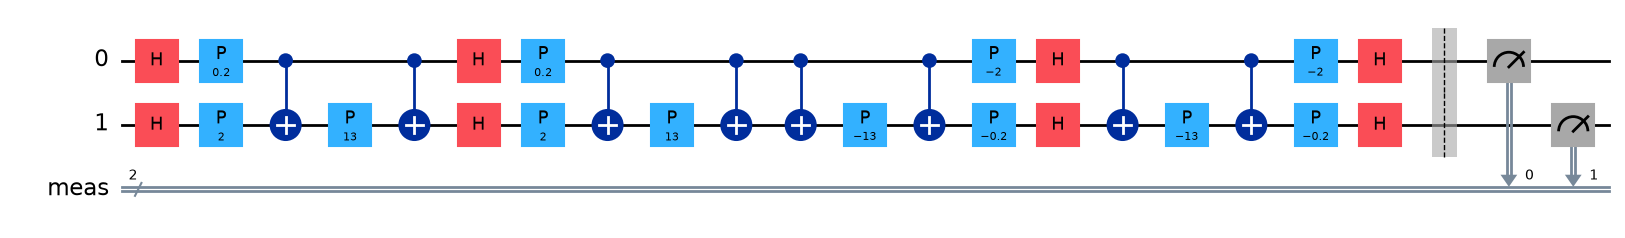

In [1]:
from QSVM import print_circuit_table, draw_smallest_circuit

print_circuit_table()
draw_smallest_circuit("kernel_circuit_2q.png")

### Changes since Phase 2: data preprocessing

The Phase 2 feedback raised two open points about the data. This is how we resolved them.

**Reducing 30 features to 2 or 4.** We use a three-step scikit-learn pipeline:

1. `StandardScaler`: every feature gets zero mean and unit variance. The raw features have very different units (for example, mean area is in the hundreds while smoothness is around 0.1). Without this step, PCA would just pick the features with the largest numbers.
2. `PCA(n_components = 2 or 4)`: keeps the directions of largest variance, one per qubit. On the 10-patient training subset, 2 components keep 76.5% of the variance and 4 keep 91.0% (printed in the Results tables).
3. `MinMaxScaler(feature_range=(0, π), clip=True)`: maps each component to $[0, \pi]$ so it can be used as a rotation angle, as planned in Phase 2.

**One fixed test set.** Phase 2 described the test set both as a fixed 20% split and as "the rest" of the data. We use the fixed split: one stratified 80/20 split (`random_state=42`) gives a pool of 455 training patients and a test set of 114 patients. Every experiment uses the same 114 test patients. Training subsets (10 now; 10, 20, 50 and 100 in Phase 4) are drawn from the 455-patient pool only, and pool patients outside the subset are not used at all.

**No test-set leakage.** The scaler, the PCA and the $[0, \pi]$ scaling are all fitted on the training subset only and then applied unchanged to the test set. The whole pipeline therefore sees only the `n_train` training patients, which matters for our limited-data research question. A test patient can fall outside the training range, so `clip=True` keeps its angles inside $[0, \pi]$.

**Smaller details.** Training subsets are drawn with stratification, so even 10 patients include both classes (4 malignant, 6 benign). Labels are scikit-learn's $\{0, 1\}$ (0 = malignant, 1 = benign) instead of $\{-1, +1\}$. `SVC` handles either encoding identically.

In [2]:
from preprocessing import print_split_summary

print_split_summary()

Dataset: 569 patients, 30 features (label 0 = malignant, 1 = benign)
  Training pool (80%) : 455 patients, 37.4% malignant
  Test set (20%)      : 114 patients, 36.8% malignant


## 2. Results

Two test cases, as planned: **2 PCA features on 2 qubits** and **4 PCA features on 4 qubits**, each trained on the same 10 patients and tested on the same 114. The cell below runs both, compares them with the Phase 2 prediction, and then repeats each test case on 10 different training subsets to check that the first subset is typical.

In [3]:
from experiments import run_results

cases = run_results()


=== Test case: 2 PCA features / 2 qubits, 10 training samples ===
Ran on: local Qiskit AerSimulator (noiseless), seed_simulator = seed_transpiler = 42
Shots: 1024 per kernel entry; 45 training + 1140 test kernel circuits
Training subset: 4 malignant / 6 benign; test set: 114 patients (fixed 20% split)
PCA keeps 76.5% of the training variance

Model                      | Kernel                 | Train acc | Test acc |    Gap
----------------------------------------------------------------------------------
QSVM                       | quantum, 1024 shots    |     60.0% |    64.0% |  -4.0%
QSVM (exact reference)     | quantum, statevector   |     60.0% |    64.0% |  -4.0%
Classical SVM (reference)  | RBF, C=1               |    100.0% |    91.2% |  +8.8%
Majority-class baseline    | -                      |         - |    63.2% |      -

Kernel checks (shot-based training kernel):
  min K(x, x) over training points: 1.0000   (ideal: 1)
  K_train symmetric:                True
  max |K_

2 qubits, 10 train     |          61.8% ±  5.6% |         89.1% ±  2.8%


4 qubits, 10 train     |          62.9% ±  1.8% |         87.6% ±  3.2%


### Setup

- **Where it ran:** both test cases ran locally on Qiskit's noiseless `AerSimulator`, with `seed_simulator = seed_transpiler = 42`.
- **Shots:** 1,024 per kernel entry. Each test case runs 45 training kernel circuits (the upper triangle of the 10 × 10 matrix) and 1,140 test kernel circuits (114 test × 10 training patients).
- **Reference answers:**
  - A classical SVM with an RBF kernel and the same $C = 1$, trained on the same preprocessed features. This is the classical reference the assignment asks for.
  - The same QSVM with the exact statevector kernel $|\langle\Phi(x')|\Phi(x)\rangle|^2$, which separates shot noise from everything else.
  - The majority-class baseline (always predict benign): the accuracy of a model that learned nothing.

### Results table

| Test case | Model | Kernel | Train acc | Test acc | Gap (train − test) |
|---|---|---|---|---|---|
| 2 qubits, 10 train | QSVM | quantum, 1,024 shots | 60.0% | **64.0%** | −4.0% |
| | QSVM | quantum, exact | 60.0% | 64.0% | −4.0% |
| | Classical SVM | RBF, $C=1$ | 100.0% | **91.2%** | +8.8% |
| | Majority class | – | – | 63.2% | – |
| 4 qubits, 10 train | QSVM | quantum, 1,024 shots | 100.0% | **63.2%** | +36.8% |
| | QSVM | quantum, exact | 100.0% | 62.3% | +37.7% |
| | Classical SVM | RBF, $C=1$ | 100.0% | **87.7%** | +12.3% |
| | Majority class | – | – | 63.2% | – |

Over 10 random training subsets (same test set, exact kernel), the QSVM averages **61.8% ± 5.6%** at 2 qubits and **62.9% ± 1.8%** at 4 qubits. The RBF SVM averages **89.1% ± 2.8%** and **87.6% ± 3.2%**. The single subset in the table is typical.

### Is the quantum kernel computed correctly?

Yes, to within shot noise:
- $K(x, x) = 1.000$ for every training point.
- $K_{\text{train}}$ is symmetric.
- The largest gap between a shot-based and an exact kernel entry is 0.040 at 2 qubits and 0.027 at 4 qubits. One standard deviation of shot noise on a single entry is at most $1/(2\sqrt{1024}) \approx 0.016$. The largest of 45 independent errors is typically 2–3 standard deviations, so these gaps are what shot noise alone produces.

Shot noise has almost no effect on the classifier. At 2 qubits, the shot-based and exact QSVMs reach the same accuracy (64.0%). At 4 qubits they differ by one test patient (63.2% vs 62.3%, i.e. 72 vs 71 of 114). We did not find a bug: the shot-based kernel, which runs the circuits, and the exact kernel, which computes the statevector overlaps directly, agree.

### Comparison with the Phase 2 prediction

In Phase 2 we predicted that the QSVM would perform **at least as well as the classical RBF SVM**. At 10 training samples **this does not hold**. The QSVM is 27.2 points behind at 2 qubits and 24.6 points behind at 4 qubits, and the 10-subset check shows this is not bad luck with one subset. The RBF SVM generalizes well from only 10 patients (91.2% and 87.7%). The QSVM stays at the majority-class baseline (64.0% and 63.2%, against 63.2%), so it has learned almost nothing that carries over to new patients. Our other Phase 2 prediction, at least 80% mean test accuracy with 100 training samples, is tested in Phase 4.

### Why the QSVM falls behind

Shot noise does not explain the gap, because the exact kernel gives the same accuracy. There is no device noise or optimizer, since we use a noiseless simulator and the SVM's fit is a convex problem. The cause is the quantum kernel itself, with our current feature scaling:

- **The kernel varies too fast.** The ZZ feature map uses phases $2x_i$ and $2(\pi - x_i)(\pi - x_j)$. With features spread over $[0, \pi]$, the two-qubit phase ranges over $[0, 2\pi^2] \approx [0, 19.7]$ rad. Across the feature range, the kernel therefore oscillates several times. Two patients with similar features can get a low similarity score, and two very different patients can get a high one. The RBF kernel's width (`gamma="scale"`) is set from the spread of the data, so nearby patients are always similar. That is the right assumption for this dataset.
- **2 qubits: the QSVM underfits.** The kernel values are not organized by class, so with $C = 1$ the SVM cannot fit even the 10 training patients. Its 60% training accuracy equals labelling all 10 as benign (6 of 10).
- **4 qubits: the QSVM overfits.** The mean off-diagonal kernel value drops from 0.366 at 2 qubits to 0.079 at 4 qubits, so most pairs of patients look almost unrelated. The SVM can fit each training patient on its own (100% training accuracy). A new patient, however, has a small kernel value with every training patient, so the decision function reduces to the offset $b$ and the model predicts the majority class. This explains the large generalization gap (+36.8% vs +12.3% for the RBF SVM). The effect gets worse as qubits are added.

This sets the main question for Phase 4: whether the quantum kernel improves with more training data and with a narrower feature range (a smaller scaling than $[0, \pi]$, which slows the kernel's oscillation), while keeping the comparison with the RBF SVM fair.

## 3. Plan for Phase 4

> **TODO (Person 1):** the larger instances, how they will be compared with the classical baseline, where they will run, and what still does not work.
>
> Points from the Results to include:
> - Training sizes of 10, 20, 50 and 100 with 10 repetitions each, on the same fixed 114-patient test set. `repeat_test_case` in `experiments.py` already does this with the exact kernel and can be switched to the shot-based kernel.
> - What still does not work: with features in $[0, \pi]$, the QSVM does no better than the majority class. Try a feature-scaling (bandwidth) factor, and possibly tune $C$ for both models, choosing both on the training data only so the comparison stays fair.

## 4. AI use

> **TODO (both):** confirm and add Person 1's use.

We used Claude (Anthropic) through Claude Code. It wrote the first version of the preprocessing and evaluation code (`preprocessing.py`, `experiments.py`), ran the experiments and the 10-subset robustness check, assembled this notebook, and drafted the text of the preprocessing changes and the Results section. In Phases 1 and 2, we used Claude to help write and edit the paragraph sections of the documents.